In [ ]:
#!pip install yfinance

In [ ]:
# importing library


import pandas as pd
import pandas_datareader.data as web
import datetime ,random
import numpy as np
import math
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Dense , Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn import preprocessing
import yfinance as yf
import scipy
import matplotlib.pyplot as plt
import copy

In [ ]:
# getting S&P500 tickers and s&p500 index

data = pd.read_html('https://en.wikipedia.org/wiki/List_of_S%26P_500_companies')
table = data[0]
sliced_table = table[1:]
header = table.iloc[0]
corrected_table = sliced_table.rename(columns=header)
tickers = corrected_table['MMM'].tolist()
tickers.append('MMM')

tickers.append('^GSPC')

tickers = tickers[::-1]

tickers

['^GSPC',
 'MMM',
 'ZTS',
 'ZION',
 'ZBH',
 'ZBRA',
 'YUM',
 'XYL',
 'XEL',
 'WYNN',
 'GWW',
 'WTW',
 'WMB',
 'WHR',
 'WY',
 'WRK',
 'WDC',
 'WST',
 'WELL',
 'WFC',
 'WEC',
 'WAT',
 'WM',
 'WBD',
 'WMT',
 'WBA',
 'WAB',
 'VMC',
 'VNO',
 'V',
 'VICI',
 'VTRS',
 'VFC',
 'VRTX',
 'VZ',
 'VRSK',
 'VRSN',
 'VTR',
 'VLO',
 'UHS',
 'UNH',
 'URI',
 'UPS',
 'UAL',
 'UNP',
 'ULTA',
 'UDR',
 'USB',
 'TSN',
 'TYL',
 'TWTR',
 'TFC',
 'TRMB',
 'TRV',
 'TDG',
 'TT',
 'TSCO',
 'TJX',
 'TMO',
 'TXT',
 'TXN',
 'TSLA',
 'TER',
 'TFX',
 'TDY',
 'TEL',
 'TGT',
 'TPR',
 'TTWO',
 'TROW',
 'TMUS',
 'SYY',
 'SNPS',
 'SYF',
 'SIVB',
 'SYK',
 'STE',
 'STT',
 'SBUX',
 'SWK',
 'LUV',
 'SO',
 'SEDG',
 'SNA',
 'SJM',
 'SWKS',
 'SPG',
 'SBNY',
 'SHW',
 'NOW',
 'SRE',
 'SEE',
 'STX',
 'SLB',
 'SBAC',
 'CRM',
 'SPGI',
 'RCL',
 'ROST',
 'ROP',
 'ROL',
 'ROK',
 'RHI',
 'RMD',
 'RSG',
 'RF',
 'REGN',
 'REG',
 'O',
 'RTX',
 'RJF',
 'RL',
 'DGX',
 'QCOM',
 'PWR',
 'QRVO',
 'PVH',
 'PHM',
 'PSA',
 'PTC',
 'PEG',
 'PRU',
 'PL

In [ ]:
#generating matrix n * m  of adj close of all ticker. each row belongs to return of all tickers+index in one day.

# remove all tickers which have missing values in their data in our selected date(2011 to 2022.5)


matrix_data = []
matrix_data_return = []

for symbol in tickers:
    try:
#        url = 'https://query1.finance.yahoo.com/v7/finance/download/' + symbol + '?period1=' + str(start) + '&period2=' + str(end) + '&interval=1d&events=history'
#        df = pd.read_csv(url)
        df = yf.download(symbol, start='2011-01-01', end='2022-01-01')
        df = df.dropna()
        matrix_data.append(df)
        print(tickers.index(symbol) , ' : ' , symbol)
    except:
        print('can not get data : ' ,symbol)



date_list = []

for i in range(len(matrix_data)):
    if len(matrix_data[i]) > len(date_list) :
        date_list = list(matrix_data[i].index)


new_matrix_data = []
for i in range(len(matrix_data)):
    if (len(matrix_data[i]) == len(date_list)) and (all((matrix_data[i].index) == date_list)):
        new_matrix_data.append(matrix_data[i])
matrix_data = new_matrix_data





for i in range(len(matrix_data)):
    matrix_data[i] = np.array(matrix_data[i]['Adj Close'])

for i in range(len(matrix_data)):
    diff = []
    for j in range(1 , len(matrix_data[i])):
        diff.append( (matrix_data[i][j] - matrix_data[i][j-1] ) / matrix_data[i][j-1] )
    matrix_data_return.append(diff)

matrix_data = np.array(matrix_data)
matrix_data = matrix_data.transpose()

matrix_data_return = np.array(matrix_data_return)
matrix_data_return = matrix_data_return.transpose()



[*********************100%***********************]  1 of 1 completed
0  :  ^GSPC
[*********************100%***********************]  1 of 1 completed
1  :  MMM
[*********************100%***********************]  1 of 1 completed
2  :  ZTS
[*********************100%***********************]  1 of 1 completed
3  :  ZION
[*********************100%***********************]  1 of 1 completed
4  :  ZBH
[*********************100%***********************]  1 of 1 completed
5  :  ZBRA
[*********************100%***********************]  1 of 1 completed
6  :  YUM
[*********************100%***********************]  1 of 1 completed
7  :  XYL
[*********************100%***********************]  1 of 1 completed
8  :  XEL
[*********************100%***********************]  1 of 1 completed
9  :  WYNN
[*********************100%***********************]  1 of 1 completed
10  :  GWW
[*********************100%***********************]  1 of 1 completed
11  :  WTW
[*********************100%*******************

In [ ]:
matrix_data_return.shape , matrix_data.shape , matrix_data.shape[0] / 11

((2769, 447), (2770, 447), 251.8181818181818)

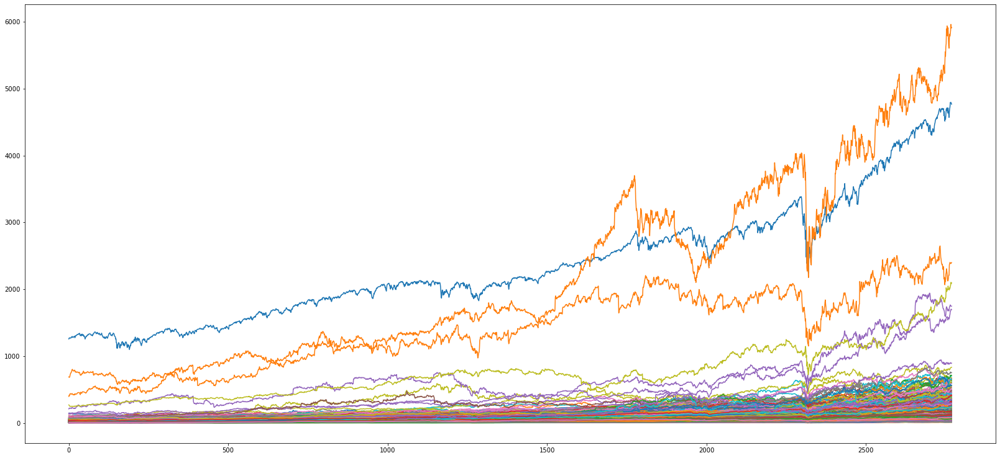

In [ ]:
plt.figure(figsize=(28,13))
plt.plot(matrix_data)
plt.show()

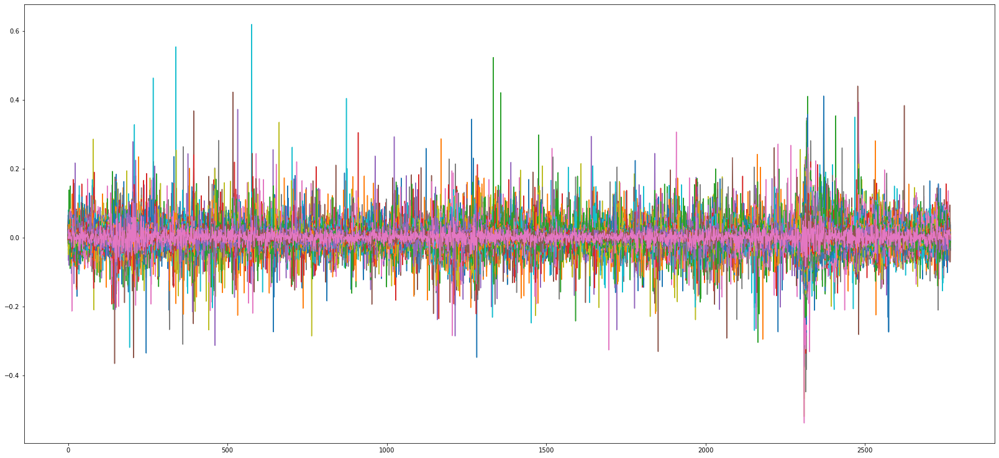

In [ ]:
plt.figure(figsize=(28,13))
plt.plot(matrix_data_return)
plt.show()

In [ ]:
# generate 5 autoencoder to predict test data independently

train_test_split = 1762

x_train = matrix_data_return[ :train_test_split , : ]
x_test = matrix_data_return[ train_test_split: , : ]
#x = preprocessing.scale(x)

main_list = []


# in main_list_second we generate model for each ticker!!
daily_each_return = []

ticker_num_list_total = []




for number in range(1000) :

    hidden_number = 4
    autoencoder = Sequential()

    autoencoder.add(Dense(30, activation = "tanh", input_shape=(x_train.shape[1], ) ))

    autoencoder.add(Dense(10, activation = "tanh"))

    autoencoder.add(Dense(hidden_number, activation = "tanh" , name = 'code'))

    autoencoder.add(Dense(10, activation = "tanh"))

    autoencoder.add(Dense(30, activation = "tanh"))

    autoencoder.add(Dense(x_train.shape[1], activation = "linear"))

 #   encoder = Model(inputs=autoencoder.input, outputs=autoencoder.get_layer('code').output)

    autoencoder.compile(optimizer='adam' , loss='mse')




    autoencoder.fit(x=x_train[:-1 , :] , y=x_train[1: , :] , batch_size = 32 , epochs=100)


    prediction = np.array(autoencoder.predict(x_test[:-1]))


    r_random = []
    r_mean = []
    r_model = []
    ticker_num_list = []

    for i in range (len(prediction)) :
        r_model.append((x_test[1: , :])[i][list(prediction[i]).index(max(prediction[i]))])
        r_random.append((x_test[1: , :])[i][random.randint(0 , matrix_data.shape[1] - 1)])
        r_mean.append(np.mean((x_test[1: , :])[i]))

        ticker_num_list.append(list(prediction[i]).index(max(prediction[i])))


    ticker_num_list_total.append(ticker_num_list)

    k_random = 1
    k_mean = 1
    k_model = 1

    for i in range(len(r_mean)) :
        k_mean = k_mean * (1+r_mean[i])

    for i in range(len(r_model)) :
        k_model = k_model * (1+r_model[i])

    for i in range(len(r_random)) :
        k_random = k_random * (1+r_random[i])

    main_list.append([k_model , k_random , k_mean])

    daily_each_return.append(r_model)

#    print(daily_each_return)


Epoch 1/100
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: unsupported operand type(s) for -: 'NoneType' and 'int'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: unsupported operand type(s) for -: 'NoneType' and 'int'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


2022-09-18 00:04:54.680504: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:116] None of the MLIR optimization passes are enabled (registered 2)
2022-09-18 00:04:54.680912: W tensorflow/core/platform/profile_utils/cpu_utils.cc:126] Failed to get CPU frequency: 0 Hz


56/56 [==============================] - 0s 555us/step - loss: 3.2309e-04
Epoch 2/100
56/56 [==============================] - 0s 548us/step - loss: 2.8660e-04
Epoch 3/100
56/56 [==============================] - 0s 536us/step - loss: 2.8895e-04
Epoch 4/100
56/56 [==============================] - 0s 532us/step - loss: 2.8666e-04
Epoch 5/100
56/56 [==============================] - 0s 536us/step - loss: 3.0697e-04
Epoch 6/100
56/56 [==============================] - 0s 538us/step - loss: 2.8166e-04
Epoch 7/100
56/56 [==============================] - 0s 520us/step - loss: 2.7646e-04
Epoch 8/100
56/56 [==============================] - 0s 542us/step - loss: 2.7566e-04
Epoch 9/100
56/56 [==============================] - 0s 533us/step - loss: 2.7732e-04
Epoch 10/100
56/56 [==============================] - 0s 520us/step - loss: 2.7580e-04
Epoch 11/100
56/56 [==============================] - 0s 529us/step - loss: 2.8197e-04
Epoch 12/100
56/56 [==============================] - 0s 532us/s

In [ ]:
# 4 year test & 7 year train
main_list_np = np.array(main_list)
main_list


# model strategy
print('average return of all model strategy : ' , np.mean(main_list_np[: , 0]))

# maximum return of model strategy
print('maximum return of all model strategy : ' , np.max(main_list_np[: , 0]))

# minimum return of model strategy
print('minimum return of all model strategy : ' , np.min(main_list_np[: , 0]))

# std return of model strategy
print('std of returns of all models strategy : ' , np.std(main_list_np[: , 0]))
# note: mean == average !

# average 5% best return of model strategy
print('average 5% best return of model strategy  : ' , np.mean(np.array(sorted(list((main_list_np[: , 0])))[-int(main_list_np.shape[0]/20):])))

# average 5% worst return of model strategy
print('average 5% worst return of model strategy : ' , np.mean(np.array(sorted(list((main_list_np[: , 0])))[:int(main_list_np.shape[0]/20)])))



print('\n\n')


# random strategy
print('average return of all random strategy : ' , np.mean(main_list_np[: , 1]))

# maximum random strategy
print('maximum return of all random strategy : ' , np.max(main_list_np[: , 1]))

# minimum random strategy
print('minumum return of all random strategy : ' , np.min(main_list_np[: , 1]))

# std return of random strategy
print('std of returns of all models strategy : ' , np.std(main_list_np[: , 1]))
# note: mean == average !

# average 5% best return of random strategy
print('average 5% best return of model strategy  : ' , np.mean(np.array(sorted(list((main_list_np[: , 1])))[-int(main_list_np.shape[0]/20):])))

# average 5% worst return of random strategy
print('average 5% worst return of model strategy : ' , np.mean(np.array(sorted(list((main_list_np[: , 1])))[:int(main_list_np.shape[0]/20)])))


# mean
#print(np.mean(main_list_np[: , 2]))

average return of all model strategy :  7.58565282131353
maximum return of all model strategy :  35.843701923084495
minimum return of all model strategy :  0.8344597082876845
std of returns of all models strategy :  5.453443410866814
average 5% best return of model strategy  :  24.511147103232332
average 5% worst return of model strategy :  1.628359186601101



average return of all random strategy :  1.995375085847797
maximum return of all random strategy :  8.785953102108936
minumum return of all random strategy :  0.268586554719433
std of returns of all models strategy :  1.201089387580525
average 5% best return of model strategy  :  5.517613152463329
average 5% worst return of model strategy :  0.5515032269870709


In [ ]:
np.mean(np.array(sorted(list((main_list_np[: , 0])))[:int(main_list_np.shape[0]/20)]))

1.628359186601101

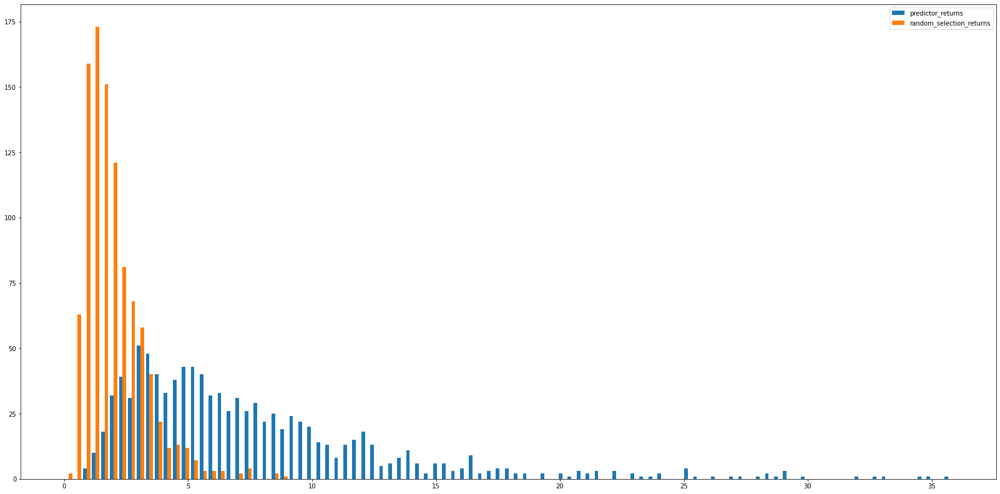

In [ ]:
# hist of all random & model returns mentions befor!

#1000 predictor : r1,r2, ... r1000
#1000 random random : 1_ran1 , r_rand2 , .... , r_rand1000

max_r = np.max(main_list_np)
bins = np.linspace(0, max_r, 100)
plt.figure(figsize=(28 , 14))
plt.hist((main_list_np[: , 0] , main_list_np[: , 1]), bins , label=['predictor_returns','random_selection_returns'] )
plt.legend(loc='upper right')
plt.show()

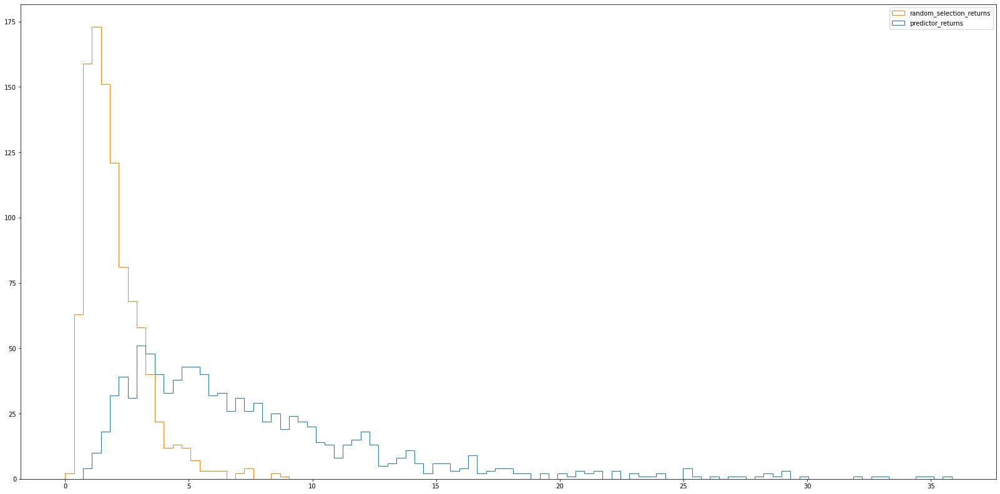

In [ ]:
# line hist of all random & model returns mentions befor!

#1000 predictor : r1,r2, ... r1000
#1000 random random : 1_ran1 , r_rand2 , .... , r_rand1000

max_r = np.max(main_list_np)
bins = np.linspace(0, max_r, 100)
plt.figure(figsize=(28 , 14))
plt.hist((main_list_np[: , 0] , main_list_np[: , 1]), bins , label=['predictor_returns','random_selection_returns'] , histtype=u'step')
plt.legend(loc='upper right')
plt.show()

In [ ]:
daily_each_return_copy = copy.deepcopy(daily_each_return)

In [ ]:

daily_each_return = np.array(daily_each_return)
daily_each_return.shape

for i in range(daily_each_return.shape[0]):
    for j in range(daily_each_return.shape[1]):
        if j == 0 :
            daily_each_return[i][j] = 1+daily_each_return[i][j]
        else :
            daily_each_return[i][j] = (daily_each_return[i][j] + 1 ) * daily_each_return[i][j-1]
daily_each_return = daily_each_return.transpose()

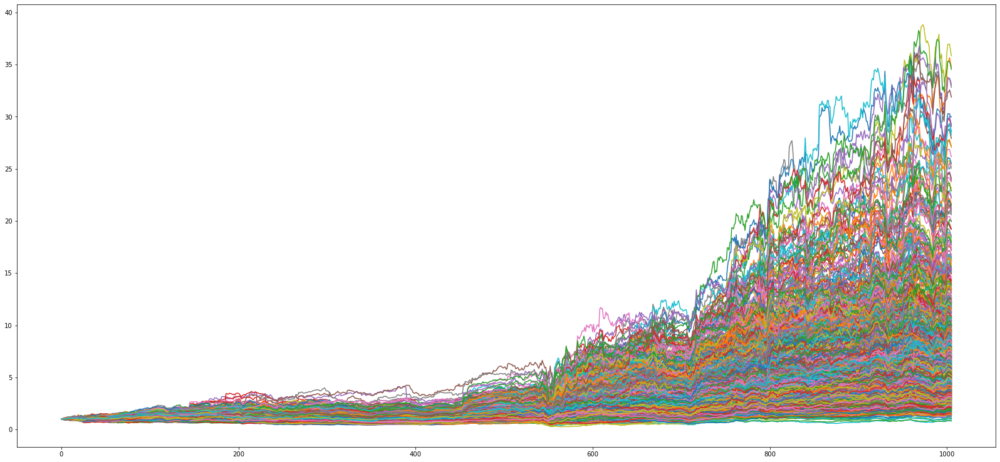

In [ ]:
# return of each model
plt.figure(figsize=(28,13))
plt.plot(daily_each_return)
plt.show()

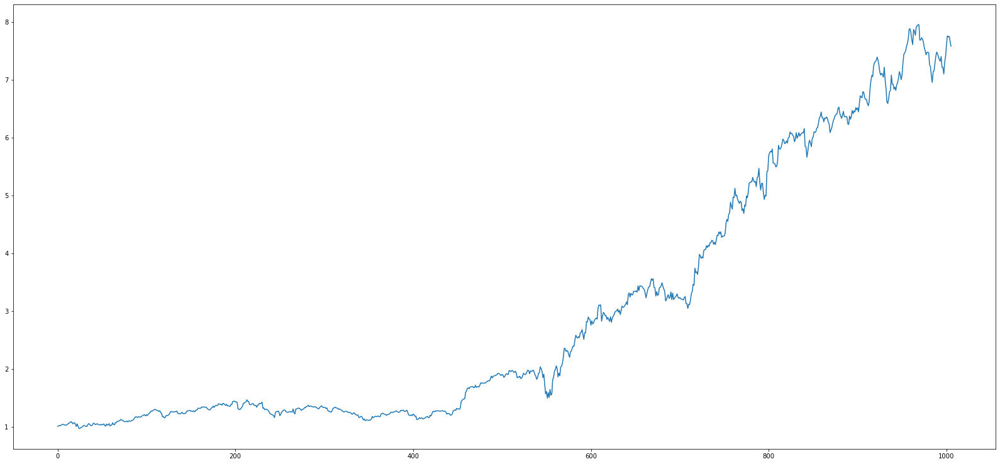

In [ ]:
# average return of all model
plt.figure(figsize=(28,13))
plt.plot(daily_each_return.mean(axis=1))
plt.show()

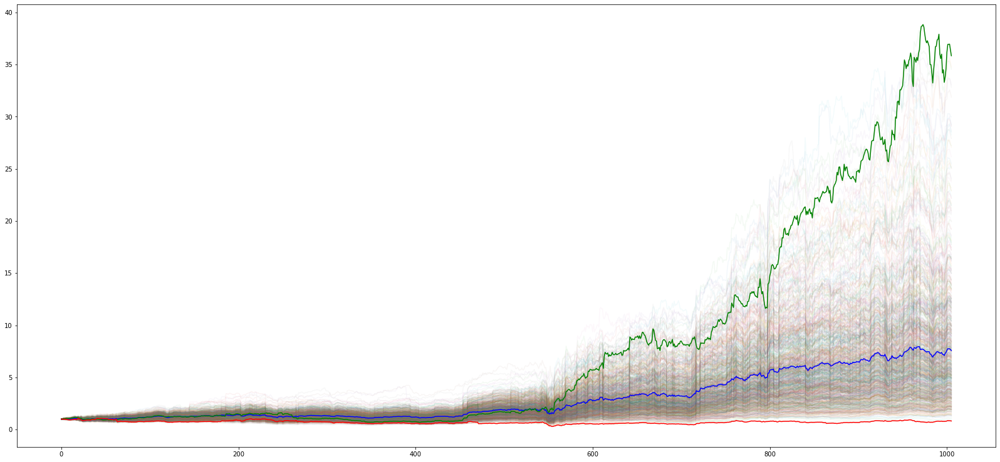

In [ ]:
# return of best(green) & worst(red) & avg(blue) and all other return
max_index_r = list(daily_each_return[ -1 , :]).index(max(list(daily_each_return[ -1 , :])))
min_index_r = list(daily_each_return[ -1 , :]).index(min(list(daily_each_return[ -1 , :])))
plt.figure(figsize=(28,13))
plt.plot(daily_each_return , alpha=0.05)
plt.plot(daily_each_return.mean(axis=1) , 'b')
plt.plot(daily_each_return[: , max_index_r] , 'g')
plt.plot(daily_each_return[: , min_index_r] , 'r')
plt.show()

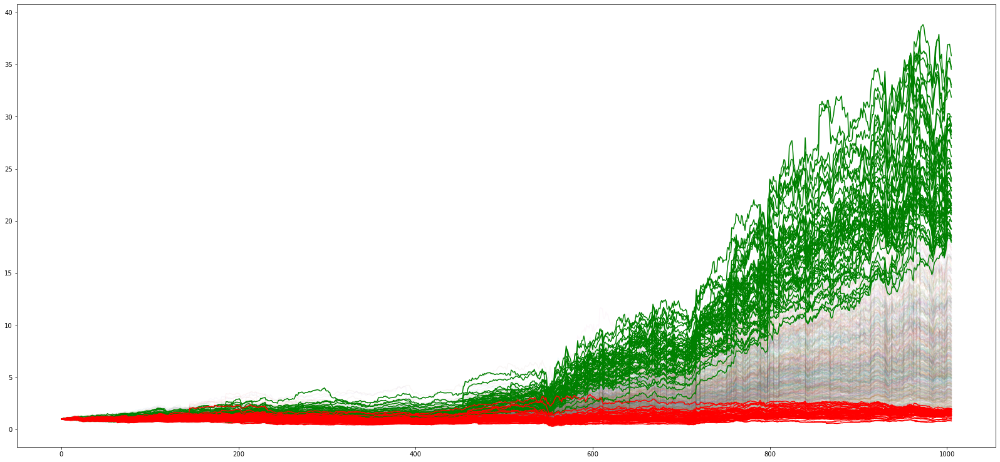

In [ ]:
best_returns = []
worst_returns = []

best_limit = sorted(list(daily_each_return[daily_each_return.shape[0]-1]))[int(daily_each_return.shape[1] * 0.95)]
worst_limit = sorted(list(daily_each_return[daily_each_return.shape[0]-1]))[int(daily_each_return.shape[1] * 0.05)]

for i in range(daily_each_return.shape[1]):
    if daily_each_return[: , i][-1] <= worst_limit :
        worst_returns.append(daily_each_return[: , i])
    if daily_each_return[: , i][-1] >= best_limit :
        best_returns.append(daily_each_return[: , i])

best_returns , worst_returns = np.array(best_returns).transpose() , np.array(worst_returns).transpose()
plt.figure(figsize=(28,13))
plt.plot(daily_each_return , alpha=0.05)
#plt.plot(daily_each_return.mean(axis=1) , 'b')
#plt.plot(daily_each_return[: , max_index_r] , 'g')
#plt.plot(daily_each_return[: , min_index_r] , 'r')
plt.plot(best_returns , 'g')
plt.plot(worst_returns , 'r')
plt.show()

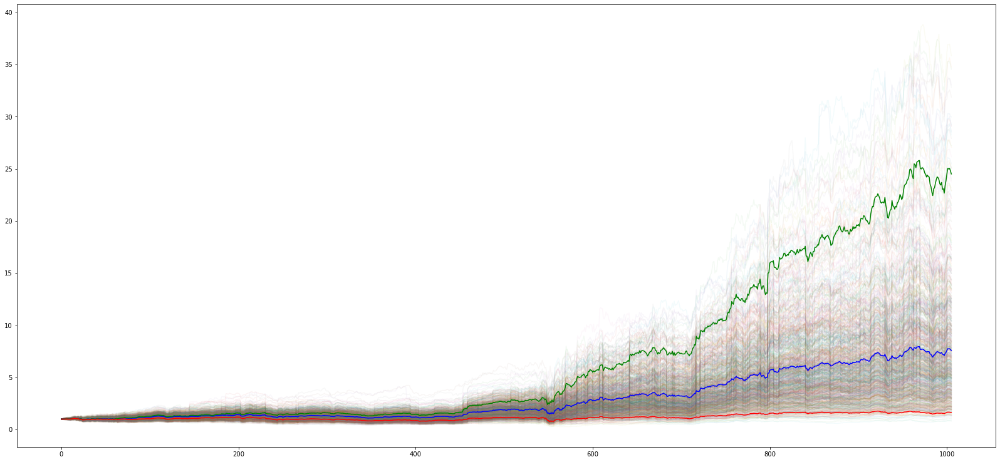

In [ ]:
best_returns = []
worst_returns = []

best_limit = sorted(list(daily_each_return[daily_each_return.shape[0]-1]))[int(daily_each_return.shape[1] * 0.95)]
worst_limit = sorted(list(daily_each_return[daily_each_return.shape[0]-1]))[int(daily_each_return.shape[1] * 0.05)]

for i in range(daily_each_return.shape[1]):
    if daily_each_return[: , i][-1] <= worst_limit :
        worst_returns.append(daily_each_return[: , i])
    if daily_each_return[: , i][-1] >= best_limit :
        best_returns.append(daily_each_return[: , i])

best_returns , worst_returns = np.array(best_returns).transpose() , np.array(worst_returns).transpose()
plt.figure(figsize=(28,13))
plt.plot(daily_each_return , alpha=0.05)
plt.plot(daily_each_return.mean(axis=1) , 'b')
#plt.plot(daily_each_return[: , max_index_r] , 'g')
#plt.plot(daily_each_return[: , min_index_r] , 'r')
plt.plot(best_returns.mean(axis = 1) , 'g')
plt.plot(worst_returns.mean(axis=1) , 'r')
plt.show()

In [ ]:
ticker_num_list_total = np.array(ticker_num_list_total)
ticker_num_list_total = ticker_num_list_total.transpose()
ticker_num_list_total.shape

(1006, 1000)

In [ ]:
num_of_ticker_per_day_in_portfo = []

for i in ticker_num_list_total :
    num_of_ticker_per_day_in_portfo.append(len(set(i)))

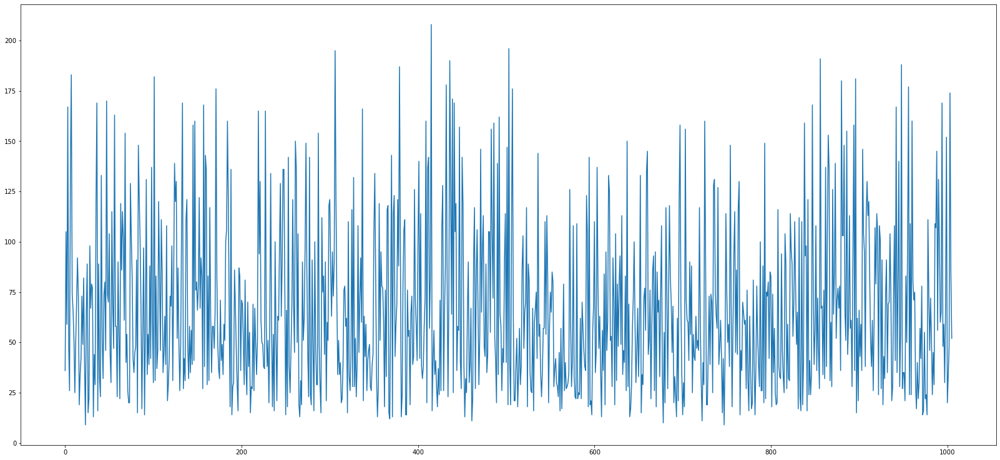

In [ ]:
plt.figure(figsize=(28,13))
plt.plot(num_of_ticker_per_day_in_portfo)
plt.show()

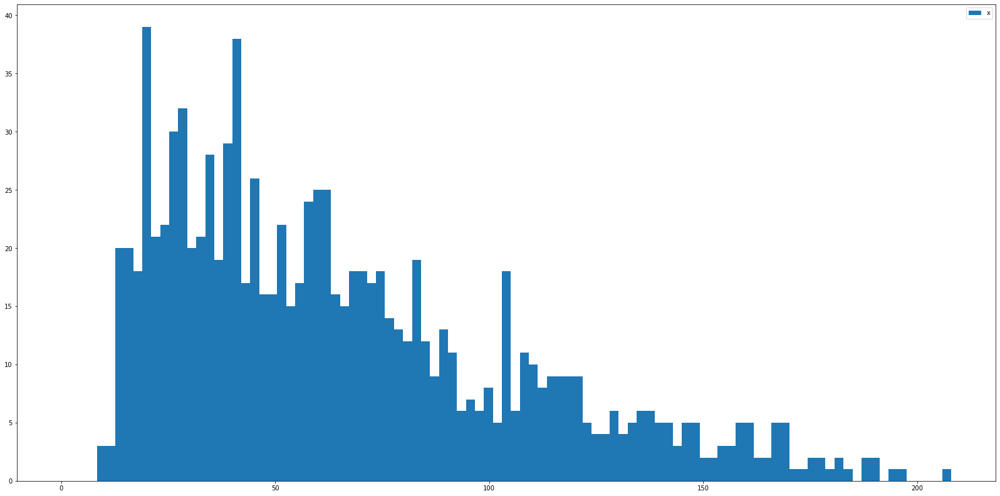

In [ ]:
max_r = np.max(num_of_ticker_per_day_in_portfo)

bins = np.linspace(0, max_r, 100)
plt.figure(figsize=(28 , 14))
plt.hist(num_of_ticker_per_day_in_portfo , bins , label=['x'])
plt.legend(loc='upper right')
plt.show()

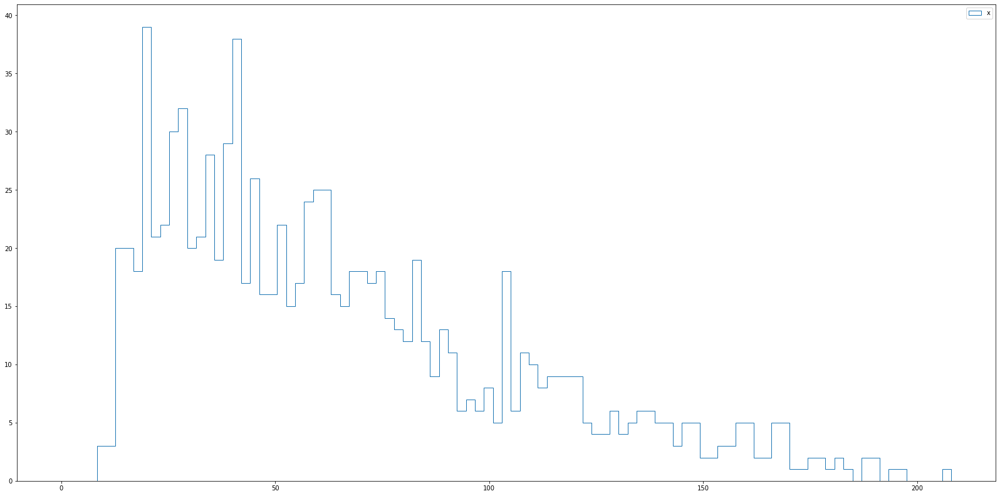

In [ ]:
max_r = np.max(num_of_ticker_per_day_in_portfo)

bins = np.linspace(0, max_r, 100)
plt.figure(figsize=(28 , 14))
plt.hist(num_of_ticker_per_day_in_portfo , bins , label=['x'] , histtype=u'step')
plt.legend(loc='upper right')
plt.show()

In [ ]:
print('min selected ticker per day : ' , min(num_of_ticker_per_day_in_portfo))
print('max selected ticker per day : ' , max(num_of_ticker_per_day_in_portfo))
print('average selected ticker per day : ' , np.mean(np.array(num_of_ticker_per_day_in_portfo)))
print('std selected ticker per day : ' , np.std(np.array(num_of_ticker_per_day_in_portfo)))
print('\n\n')

l = len((sorted(num_of_ticker_per_day_in_portfo)))

for i in range(5 , 96 , 5) :
    print(i , '% of days contains less than' , sorted(num_of_ticker_per_day_in_portfo)[int(i/100*l)] , 'tickers in portfolio')


min selected ticker per day :  9
max selected ticker per day :  208
average selected ticker per day :  66.36481113320079
std selected ticker per day :  41.25765323682931



5 % of days contains less than 17 tickers in portfolio
10 % of days contains less than 21 tickers in portfolio
15 % of days contains less than 26 tickers in portfolio
20 % of days contains less than 29 tickers in portfolio
25 % of days contains less than 34 tickers in portfolio
30 % of days contains less than 38 tickers in portfolio
35 % of days contains less than 42 tickers in portfolio
40 % of days contains less than 46 tickers in portfolio
45 % of days contains less than 52 tickers in portfolio
50 % of days contains less than 57 tickers in portfolio
55 % of days contains less than 62 tickers in portfolio
60 % of days contains less than 68 tickers in portfolio
65 % of days contains less than 74 tickers in portfolio
70 % of days contains less than 81 tickers in portfolio
75 % of days contains less than 89 tickers i

# model strategy(average of 1000 mdels) vs buy&hold(index) returns

In [ ]:
daily_each_return.mean(axis=1).shape , matrix_data.shape

((1006,), (2770, 447))

In [ ]:
index_return = list(matrix_data[train_test_split+1: , 0] / matrix_data[train_test_split+1 , 0])

In [ ]:
model_return = list(daily_each_return.mean(axis=1))
model_return.insert(0 , 1)

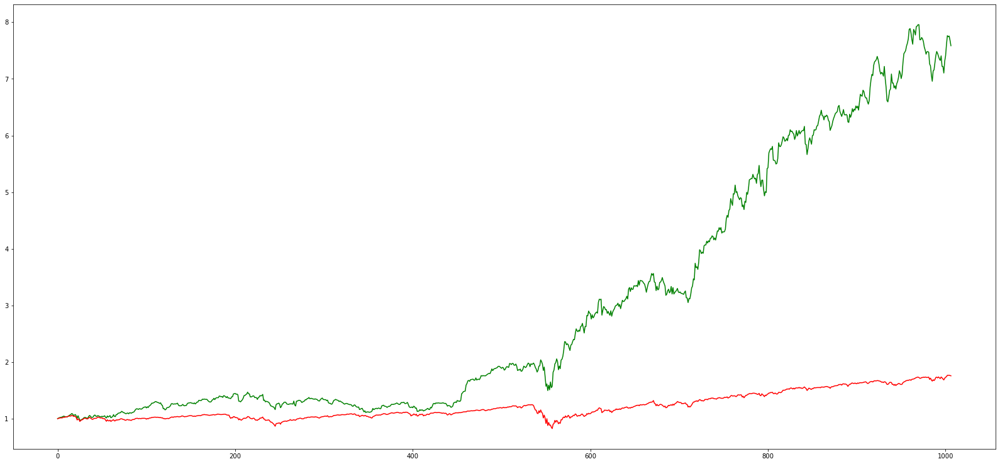

In [ ]:
plt.figure(figsize=(28,13))
plt.plot(model_return , 'g')
plt.plot(index_return , 'r')
plt.show()

In [ ]:
print('first year model return : ' , (model_return[252] - model_return[0])/model_return[0])
print('second year model return : ' , (model_return[504] - model_return[252])/model_return[252])
print('third year model return : ' , (model_return[504+251] - model_return[504])/model_return[504])
print('forth year model return : ' , (model_return[1006] - model_return[504+251])/model_return[504+251])

print('\n\n')

print('first year model return : ' , (index_return[252] - index_return[0])/index_return[0])
print('second year model return : ' , (index_return[504] - index_return[252])/index_return[252])
print('third year model return : ' , (index_return[504+251] - index_return[504])/index_return[504])
print('forth year model return : ' , (index_return[1006] - index_return[504+251])/index_return[504+251])


first year model return :  0.21482392282636864
second year model return :  0.5388298975595429
third year model return :  1.437154072735606
forth year model return :  0.664968515950482



first year model return :  -0.0667586095684809
second year model return :  0.2821315293497356
third year model return :  0.13996632112642737
forth year model return :  0.28793058018340595


In [ ]:
(1.20746892814636086 * 1.5159702496093551 * 2.497549438306498 * 1.6794324105028566) ** 0.25

1.6646035502507661

In [ ]:
((1-0.0667586095684809) * 1.2821315293497356 * 1.13996632112642737 * 1.28793058018340595) ** 0.25

1.151271522027438

# risk :)

In [ ]:
sharpe_list = []

for i in range(len(daily_each_return_copy)) :
    sharpe_i = ((1 + np.mean(daily_each_return_copy[i])) ** 252 - 0.0222) / (np.std(daily_each_return_copy[i]) * (252**0.5))
    sharpe_list.append(sharpe_i)



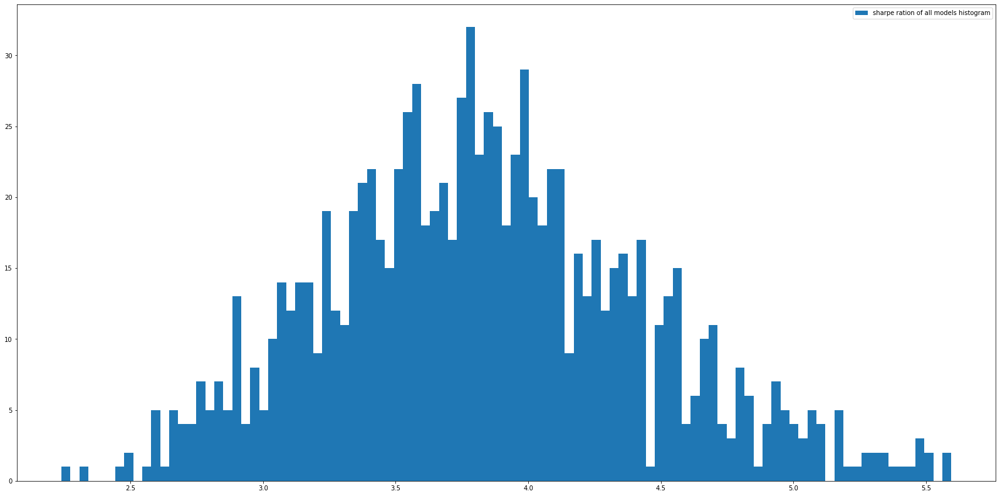

In [ ]:
max_r = np.max(sharpe_list)
min_r = np.min(sharpe_list)
bins = np.linspace(min_r, max_r, 100)
plt.figure(figsize=(28 , 14))
plt.hist(sharpe_list , bins , label=['sharpe ration of all models histogram'])
plt.legend(loc='upper right')
plt.show()

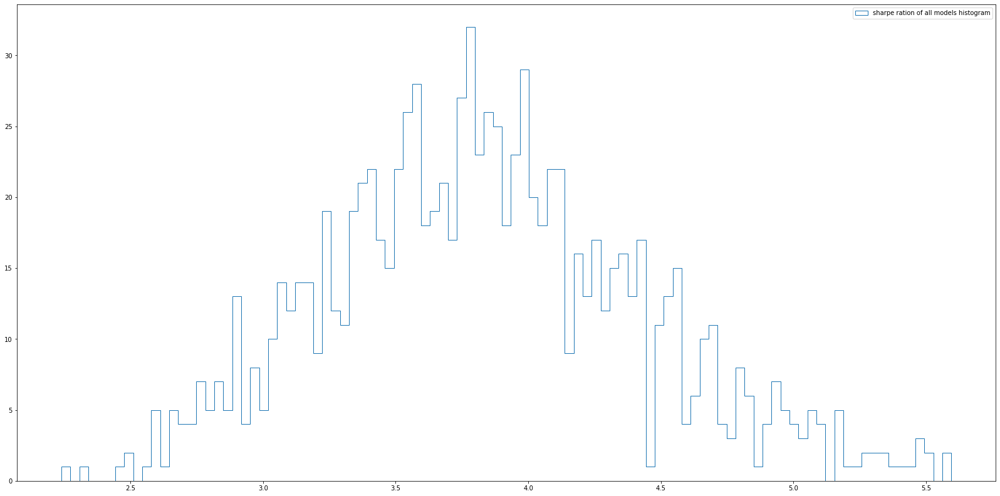

In [ ]:
max_r = np.max(sharpe_list)
min_r = np.min(sharpe_list)
bins = np.linspace(min_r, max_r, 100)
plt.figure(figsize=(28 , 14))
plt.hist(sharpe_list , bins , label=['sharpe ration of all models histogram'] , histtype=u'step')
plt.legend(loc='upper right')
plt.show()

In [ ]:
print('min sharpe ratio of all models : ' , min(sharpe_list))
print('max sharpe ratio of all models : ' , max(sharpe_list))
print('average sharpe ratio of all models : ' , np.mean(np.array(sharpe_list)))
print('std sharpe ratio of all models : ' , np.std(np.array(sharpe_list)))
print('\n\n')

l = len((sorted(sharpe_list)))

for i in range(5 , 96 , 5) :
    print(i , '% of models have sharpe ratio greater than' , sorted(sharpe_list , reverse=True)[int(i/100*l)] )


min sharpe ratio of all models :  2.239552751560706
max sharpe ratio of all models :  5.5952591038935005
average sharpe ratio of all models :  3.8319832162267744
std sharpe ratio of all models :  0.5968678863083344



5 % of models have sharpe ratio greater than 4.9182937703126415
10 % of models have sharpe ratio greater than 4.639709816836303
15 % of models have sharpe ratio greater than 4.436050376672913
20 % of models have sharpe ratio greater than 4.3273608826846415
25 % of models have sharpe ratio greater than 4.2066414830792285
30 % of models have sharpe ratio greater than 4.099380997448372
35 % of models have sharpe ratio greater than 4.01440237571947
40 % of models have sharpe ratio greater than 3.949947826759623
45 % of models have sharpe ratio greater than 3.870104439347909
50 % of models have sharpe ratio greater than 3.80304194931265
55 % of models have sharpe ratio greater than 3.74357878484162
60 % of models have sharpe ratio greater than 3.6612103418463646
65 % of models